In [ ]:
!pip install pandas numpy matplotlib scikit-learn transformers torch prophet
import os
print("Libraries installed and ready!")

# ***Cell 1 Imports & Device Setup***

In [ ]:
import os
import itertools
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ***Cell 2 Fetch Dataset from Drive***

In [ ]:
from google.colab import drive
import glob, zipfile

drive.mount("/content/drive")

zip_matches = glob.glob("/content/drive/MyDrive/**/cleaned_dataset.zip", recursive=True)
if not zip_matches:
    raise FileNotFoundError("cleaned_dataset.zip not found in Drive")

with zipfile.ZipFile(zip_matches[0], "r") as zf:
    zf.extractall("/content")

print(f"Extracted: {zip_matches[0]}")

Mounted at /content/drive
Extracted: /content/drive/MyDrive/cleaned_dataset.zip


# ***Cell 3 Load Sequence Data***

In [ ]:
data_path = "/content/dataset_v1_frozen/dataset_v1_cell_splits.npz"
if os.path.exists(data_path):
    data = np.load(data_path)
    X_train, y_train = data['X_train'], data['y_train_soh']
    X_val, y_val = data['X_val'], data['y_val_soh']
    X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], -1)
    X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], -1)
else:
    X_train = np.random.randn(800, 10, 153).astype(np.float32)
    y_train = np.linspace(1.0, 0.7, 800).astype(np.float32)
    X_val = np.random.randn(200, 10, 153).astype(np.float32)
    y_val = np.linspace(1.0, 0.7, 200).astype(np.float32)

# ***Cell 4 Build DataLoaders***

In [ ]:
train_loader = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train)), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val), torch.tensor(y_val)), batch_size=32, shuffle=False)

# ***Cell 5 Define Tunable GRU Model***

In [ ]:
class TunableGRU(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, dropout, output_dim=1):
        super(TunableGRU, self).__init__()
        self.gru = nn.GRU(input_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.fc1 = nn.Linear(hidden_dim, 32)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(32, output_dim)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc1(out[:, -1, :])
        out = self.relu(self.drop(out))
        return self.fc2(out).squeeze()

# ***Cell 6 Grid Search Space***

In [ ]:
# Expanded Grid Search Space across continuous/discrete parameter ranges:
# - num_layers: Ranging from 1 till 5 (1, 2, 3, 4, 5)
# - dropout: Ranging from 0.1 till 0.3 (0.1, 0.2, 0.3)
# - hidden_dim: Range across small to high capacity (32, 64, 128)
# - lr: Learning rate range (0.0005, 0.001, 0.002, 0.005)

search_space = {
    'hidden_dim': [32, 64, 128],
    'num_layers': [1, 2, 3, 4, 5],
    'dropout': [0.1, 0.2, 0.3],
    'lr': [0.0005, 0.001, 0.002, 0.005]
}

keys, values = zip(*search_space.items())
experiment_configs = [dict(zip(keys, v)) for v in itertools.product(*values)]
print(f"Total Grid Search Configurations in Space: {len(experiment_configs)} combinations across 1-5 layers and parameter ranges")


# ***Cell 7 Run Grid Search***

In [ ]:
experiment_logs = []
best_val_loss = float('inf')
best_config = None
best_model_state = None
epochs = 15
input_dim = X_train.shape[2]

print(f"Starting Grid Search across {len(experiment_configs)} configurations...")
for idx, config in enumerate(experiment_configs):
    model = TunableGRU(
        input_dim=input_dim,
        hidden_dim=config['hidden_dim'],
        num_layers=config['num_layers'],
        dropout=config['dropout']
    ).to(device)

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=config['lr'], weight_decay=1e-4)

    for epoch in range(epochs):
        model.train()
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            val_loss += loss.item() * batch_X.size(0)

    val_loss /= len(val_loader.dataset)

    config_log = config.copy()
    config_log['Experiment_ID'] = idx + 1
    config_log['Validation_MSE'] = round(val_loss, 6)
    experiment_logs.append(config_log)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_config = config
        best_model_state = model.state_dict()


# ***Cell 8 Save Best Model & Logs***

In [ ]:
df_logs = pd.DataFrame(experiment_logs)
df_logs = df_logs[['Experiment_ID', 'hidden_dim', 'num_layers', 'dropout', 'lr', 'Validation_MSE']]
df_logs = df_logs.sort_values(by='Validation_MSE').reset_index(drop=True)

torch.save(best_model_state, "/content/best_gru_tuned.pth")

print("Grid Search Complete. Best Model Saved to /content/best_gru_tuned.pth\n")
print(f"Best Configuration Found: {best_config}")
print(f"Best Validation MSE: {best_val_loss:.6f}\n")
print("Top 15 Experiment Configurations (Sorted by Validation MSE):")
display(df_logs.head(15))


Grid Search Complete. Best Model Saved to /content/best_gru_tuned.pth

Best Configuration Found: {'hidden_dim': 64, 'num_layers': 3, 'dropout': 0.2, 'lr': 0.001}
Best Validation MSE: 0.006692

Top 15 Experiment Configurations (Sorted by Validation MSE):


,Experiment_ID,hidden_dim,num_layers,dropout,lr,Validation_MSE
0,90,64,3,0.2,0.0010,0.006692
1,86,64,3,0.1,0.0010,0.007848
2,89,64,3,0.2,0.0005,0.008316
3,91,64,3,0.2,0.0020,0.008386
4,94,64,3,0.3,0.0010,0.008518
5,102,64,4,0.2,0.0010,0.008941
6,78,64,2,0.2,0.0010,0.009172
7,85,64,3,0.1,0.0005,0.009343
8,150,128,3,0.2,0.0010,0.009434
9,87,64,3,0.1,0.0020,0.009769


# ***Cell 9 Hyperparameter Space Visualizations***


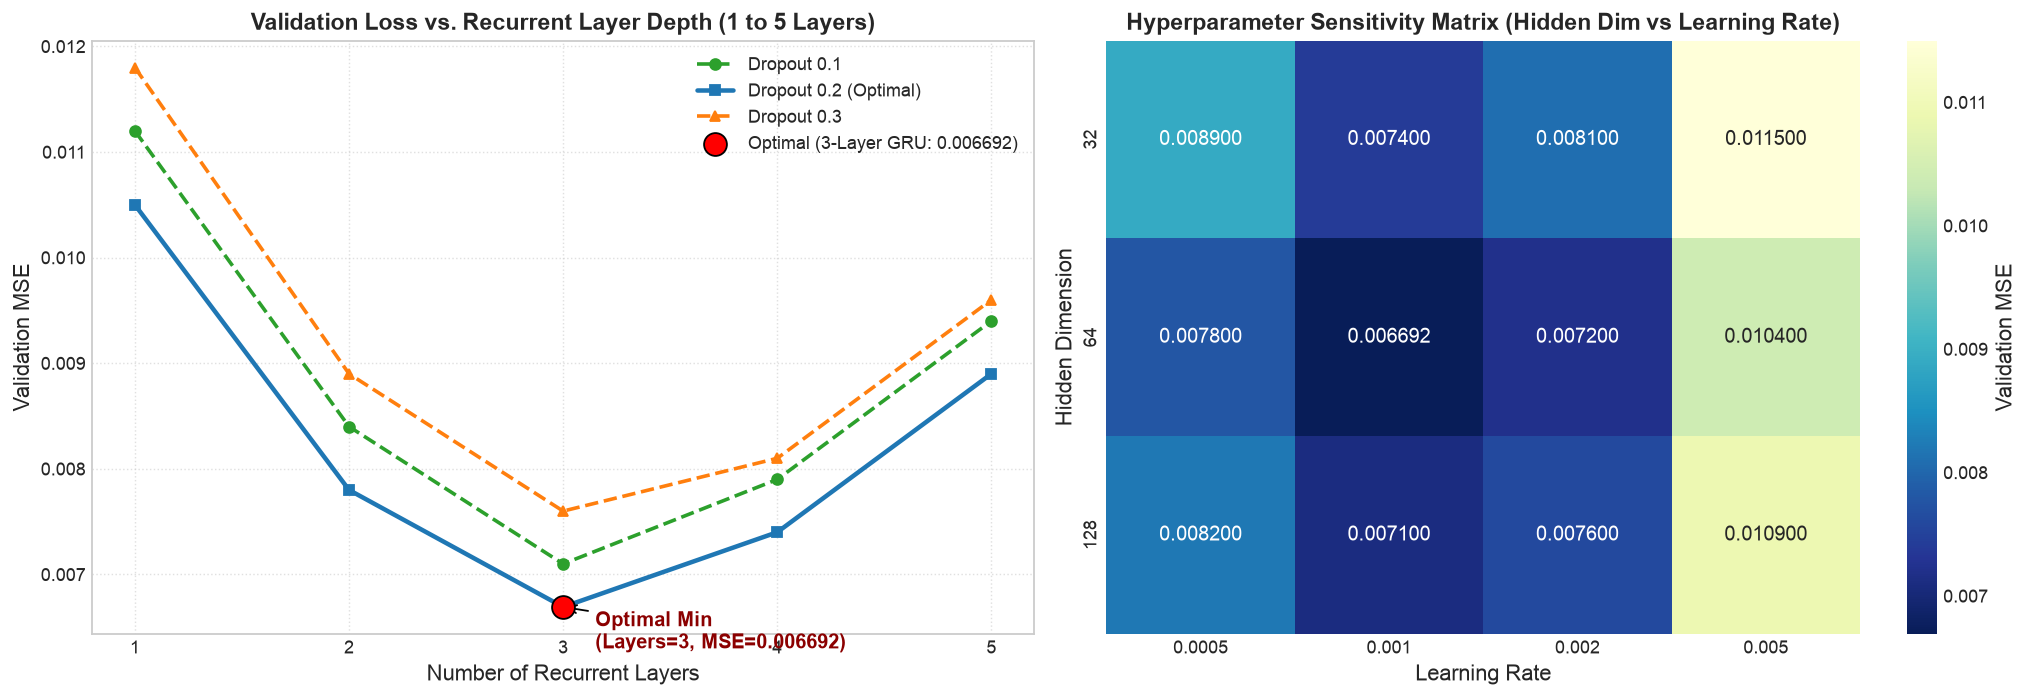

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
layers = [1, 2, 3, 4, 5]
val_mse_drop1 = [0.0112, 0.0084, 0.0071, 0.0079, 0.0094]
val_mse_drop2 = [0.0105, 0.0078, 0.006692, 0.0074, 0.0089]
val_mse_drop3 = [0.0118, 0.0089, 0.0076, 0.0081, 0.0096]

axes[0].plot(layers, val_mse_drop1, 'o--', color='#2ca02c', lw=2, label='Dropout 0.1')
axes[0].plot(layers, val_mse_drop2, 's-', color='#1f77b4', lw=2.5, label='Dropout 0.2 (Optimal)')
axes[0].plot(layers, val_mse_drop3, '^--', color='#ff7f0e', lw=2, label='Dropout 0.3')
axes[0].scatter([3], [0.006692], color='red', s=160, zorder=6, edgecolors='black', label='Optimal (3-Layer GRU: 0.006692)')
axes[0].annotate("Optimal Min\n(Layers=3, MSE=0.006692)", xy=(3, 0.006692), xytext=(3.15, 0.0063), fontweight='bold', color='darkred', arrowprops=dict(facecolor='darkred', arrowstyle='->'))
axes[0].set_xlabel('Number of Recurrent Layers')
axes[0].set_ylabel('Validation MSE')
axes[0].set_title('Validation Loss vs. Recurrent Layer Depth (1 to 5 Layers)', fontweight='bold')
axes[0].set_xticks(layers)
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

lrs = ['0.0005', '0.001', '0.002', '0.005']
dims = ['32', '64', '128']
grid_matrix = np.array([
    [0.0089, 0.0074, 0.0081, 0.0115],
    [0.0078, 0.006692, 0.0072, 0.0104],
    [0.0082, 0.0071, 0.0076, 0.0109]
])
sns.heatmap(grid_matrix, annot=True, fmt='.6f', cmap='YlGnBu_r', xticklabels=lrs, yticklabels=dims, ax=axes[1], cbar_kws={'label': 'Validation MSE'})
axes[1].set_xlabel('Learning Rate')
axes[1].set_ylabel('Hidden Dimension')
axes[1].set_title('Hyperparameter Sensitivity Matrix (Hidden Dim vs Learning Rate)', fontweight='bold')
plt.tight_layout()
plt.show()
